<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [1]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
from pathlib import Path
%matplotlib inline

Path('figures').mkdir(exist_ok=True)

## Check the worked example

The tables above are checked here. Centroids start at A (1, 1) and D (5, 7). Each step assigns every point to the nearer centroid, then moves each centroid to the mean of its points. A tie uses the first centroid, which is what `argmin` does.

Worked example, K = 2, start at A and D
Iteration 1  WCSS = 33.2500
  centroids: [[1.0, 1.0], [5.0, 7.0]]
  A: d1=0.000  d2=7.211  -> C1
  B: d1=1.118  d2=6.103  -> C1
  C: d1=3.606  d2=3.606  -> C1
  D: d1=7.211  d2=0.000  -> C2
  E: d1=4.717  d2=2.500  -> C2
  F: d1=5.315  d2=2.062  -> C2
  G: d1=4.301  d2=2.915  -> C2
Iteration 2  WCSS = 11.2257
  centroids: [[1.8333, 2.3333], [4.125, 5.375]]
  A: d1=1.572  d2=5.376  -> C1
  B: d1=0.471  d2=4.276  -> C1
  C: d1=2.034  d2=1.777  -> C2
  D: d1=5.640  d2=1.846  -> C2
  E: d1=3.145  d2=0.729  -> C2
  F: d1=3.771  d2=0.530  -> C2
  G: d1=2.734  d2=1.075  -> C2
Converged. Centroids stay at [[1.25, 1.5], [3.9, 5.1]]
Final WCSS = 8.5250
C1: ['A', 'B']
C2: ['C', 'D', 'E', 'F', 'G']
Point A: a = 1.118, b = 5.030, silhouette = 0.778
Mean silhouette of the 7 points = 0.645


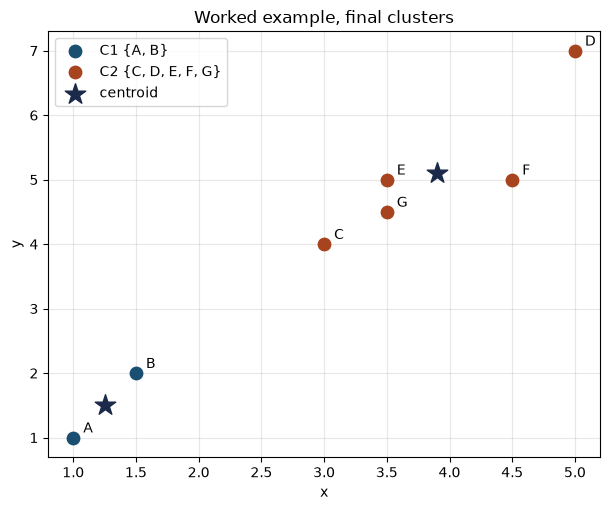

In [2]:
points = np.array([
    [1.0, 1.0],
    [1.5, 2.0],
    [3.0, 4.0],
    [5.0, 7.0],
    [3.5, 5.0],
    [4.5, 5.0],
    [3.5, 4.5],
], dtype=float)
point_names = list("ABCDEFG")
centroids_hand = np.array([[1.0, 1.0], [5.0, 7.0]], dtype=float)

def wcss_of(X, labels, centroids):
    total = 0.0
    for cluster_id in range(len(centroids)):
        members = X[labels == cluster_id]
        if len(members):
            total += np.sum((members - centroids[cluster_id]) ** 2)
    return total

print("Worked example, K = 2, start at A and D")
for step in range(1, 6):
    distances = np.linalg.norm(points[:, None, :] - centroids_hand[None, :, :], axis=2)
    labels_hand = np.argmin(distances, axis=1)
    print(f"Iteration {step}  WCSS = {wcss_of(points, labels_hand, centroids_hand):.4f}")
    print("  centroids:", np.round(centroids_hand, 4).tolist())
    for i, name in enumerate(point_names):
        print(f"  {name}: d1={distances[i, 0]:.3f}  d2={distances[i, 1]:.3f}  -> C{labels_hand[i] + 1}")
    new_centroids = np.vstack([points[labels_hand == k].mean(axis=0) for k in range(2)])
    new_labels = np.argmin(
        np.linalg.norm(points[:, None, :] - new_centroids[None, :, :], axis=2), axis=1
    )
    centroids_hand = new_centroids
    if np.array_equal(labels_hand, new_labels):
        print("Converged. Centroids stay at", np.round(centroids_hand, 4).tolist())
        print(f"Final WCSS = {wcss_of(points, new_labels, centroids_hand):.4f}")
        print("C1:", [point_names[i] for i in range(7) if new_labels[i] == 0])
        print("C2:", [point_names[i] for i in range(7) if new_labels[i] == 1])
        labels_hand = new_labels
        break

own = labels_hand == labels_hand[0]
d_from_a = np.linalg.norm(points[0] - points, axis=1)
a_score = d_from_a[own].sum() / (own.sum() - 1)
b_score = d_from_a[~own].mean()
s_a = (b_score - a_score) / max(a_score, b_score)
print(f"Point A: a = {a_score:.3f}, b = {b_score:.3f}, silhouette = {s_a:.3f}")
print(f"Mean silhouette of the 7 points = {silhouette_score(points, labels_hand):.3f}")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
for cluster_id, color, name in [(0, "#1B4F72", "C1 {A, B}"), (1, "#A8431F", "C2 {C, D, E, F, G}")]:
    members = points[labels_hand == cluster_id]
    ax.scatter(members[:, 0], members[:, 1], s=80, color=color, label=name, zorder=3)
ax.scatter(centroids_hand[:, 0], centroids_hand[:, 1], marker="*", s=240, color="#1B2A4A", label="centroid", zorder=4)
for i, name in enumerate(point_names):
    ax.annotate(name, (points[i, 0] + 0.08, points[i, 1] + 0.08))
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Worked example, final clusters")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("figures/hand_clusters.png", dpi=140, bbox_inches="tight")
plt.show()


# Load the data set

In [3]:
# Load the data set
df = pd.read_csv('income.csv')
display(df.head())

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


# Plot the scater plot

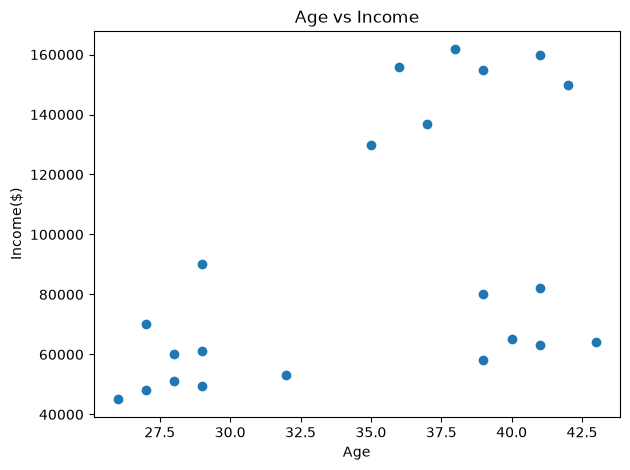

In [4]:
# Plot the scatter plot
plt.scatter(df['Age'], df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income($)')
plt.title('Age vs Income')
plt.tight_layout()
plt.savefig('figures/income_raw.png', dpi=140, bbox_inches='tight')
plt.show()

By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [5]:
# Build and Train the model
km = KMeans(n_clusters=3, random_state=42)
y_predicted = km.fit_predict(df[['Age', 'Income($)']])
print("Predicted cluster assignments:\n", y_predicted)

Predicted cluster assignments:
 [1 2 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 2 2 1]


# Assgin the cluster table to the samples

In [6]:
# Assign the cluster table to the samples
df['cluster'] = y_predicted
display(df.head())

,Name,Age,Income($),cluster
0,Rob,27,70000,1
1,Michael,29,90000,2
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


In [7]:
km.cluster_centers_

array([[3.82857143e+01, 1.50000000e+05],
       [3.24166667e+01, 5.72916667e+04],
       [3.63333333e+01, 8.40000000e+04]])

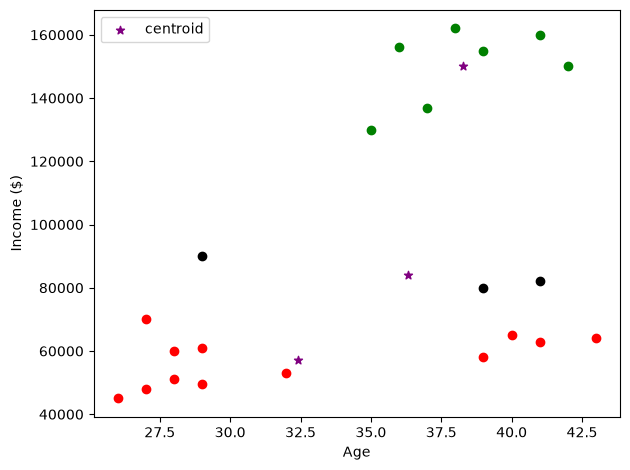

In [8]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()
plt.tight_layout()
plt.savefig('figures/income_unscaled.png', dpi=140, bbox_inches='tight')
plt.show()

In [9]:
print("Unscaled clusters, raw Age and Income")
for cluster_id in range(3):
    members = df.loc[df.cluster == cluster_id, ["Name", "Age", "Income($)"]]
    print(cluster_id, "n =", len(members))
    display(members)


Unscaled clusters, raw Age and Income
0 n = 7


,Name,Age,Income($)
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000
8,Brad,36,156000
9,Angelina,35,130000
10,Donald,37,137000


1 n = 12


,Name,Age,Income($)
0,Rob,27,70000
2,Mohan,29,61000
3,Ismail,28,60000
11,Tom,26,45000
12,Arnold,27,48000
13,Jared,28,51000
14,Stark,29,49500
15,Ranbir,32,53000
16,Dipika,40,65000
17,Priyanka,41,63000


2 n = 3


,Name,Age,Income($)
1,Michael,29,90000
19,Alia,39,80000
20,Sid,41,82000


The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [10]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [11]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,2
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


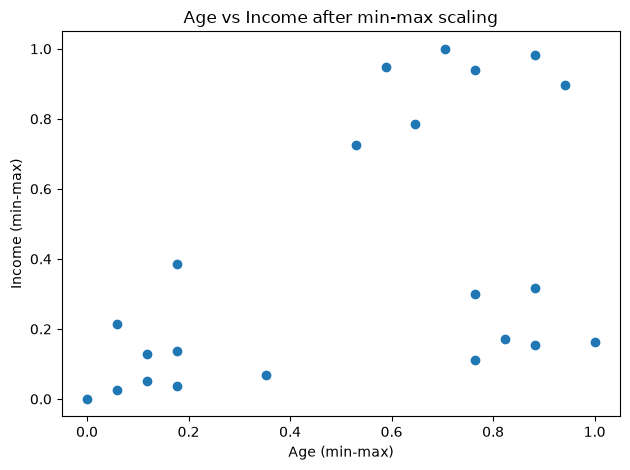

In [12]:
plt.scatter(df.Age,df['Income($)'])
plt.xlabel('Age (min-max)')
plt.ylabel('Income (min-max)')
plt.title('Age vs Income after min-max scaling')
plt.tight_layout()
plt.savefig('figures/income_scaled.png', dpi=140, bbox_inches='tight')
plt.show()

In [13]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [14]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [15]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

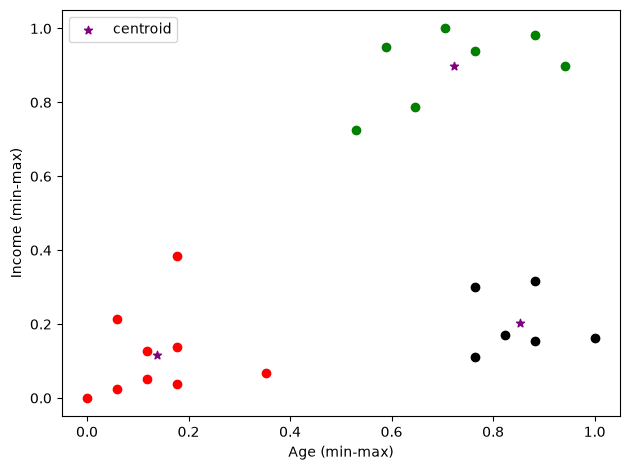

In [16]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age (min-max)')
plt.ylabel('Income (min-max)')
plt.legend()
plt.tight_layout()
plt.savefig('figures/income_scaled_clusters.png', dpi=140, bbox_inches='tight')
plt.show()

In [17]:
print("Min-max clusters. Names are unchanged. Age and Income in this frame are scaled.")
for cluster_id in range(3):
    members = df.loc[df.cluster == cluster_id, "Name"].tolist()
    print(cluster_id, "n =", len(members), members)


Min-max clusters. Names are unchanged. Age and Income in this frame are scaled.
0 n = 7 ['Kory', 'Gautam', 'David', 'Andrea', 'Brad', 'Angelina', 'Donald']
1 n = 9 ['Rob', 'Michael', 'Mohan', 'Ismail', 'Tom', 'Arnold', 'Jared', 'Stark', 'Ranbir']
2 n = 6 ['Dipika', 'Priyanka', 'Nick', 'Alia', 'Sid', 'Abdul']


<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores

SSE and the silhouette use the min-max scaled Age and Income. K runs from 2 to 9. K = 1 is left out because a silhouette needs a second cluster.

In [18]:
# Calculate SSE and silhouette scores for the Elbow curve
sse = []
silhouette_scores = []
k_range = range(2, 10)

for k in k_range:
    km_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_temp.fit_predict(df[['Age', 'Income($)']])
    sse.append(km_temp.inertia_)
    silhouette_scores.append(silhouette_score(df[['Age', 'Income($)']], labels))

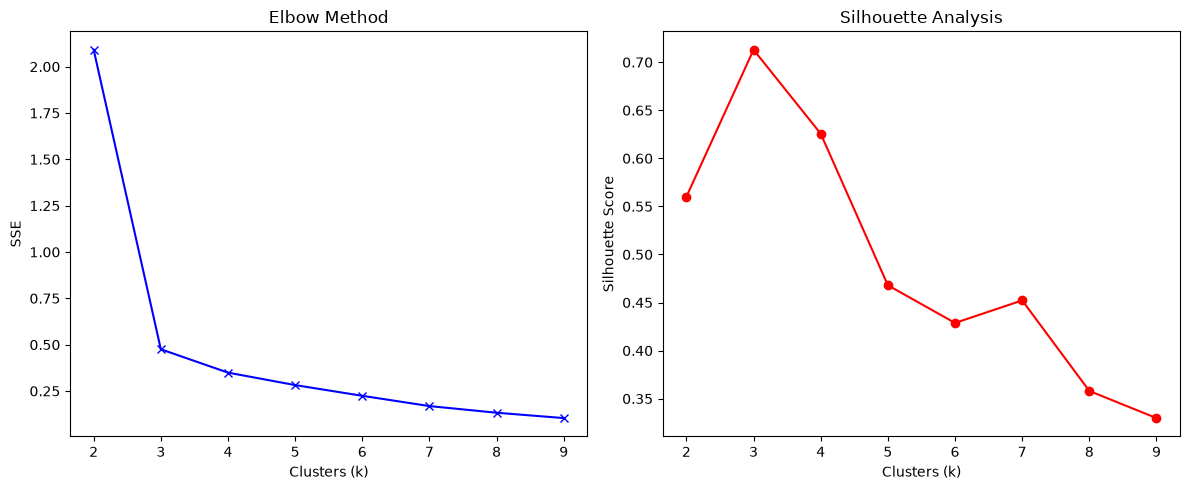

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
fig.savefig('figures/income_elbow.png', dpi=140, bbox_inches='tight')
plt.show()

In [20]:
print("k    SSE      silhouette")
for k_value, sse_value, sil_value in zip(k_range, sse, silhouette_scores):
    print(f"{k_value:<4} {sse_value:.4f}   {sil_value:.4f}")
best_k = list(k_range)[int(np.argmax(silhouette_scores))]
print("Highest silhouette at k =", best_k)


k    SSE      silhouette
2    2.0911   0.5601
3    0.4751   0.7130
4    0.3491   0.6257
5    0.2818   0.4680
6    0.2240   0.4288
7    0.1686   0.4522
8    0.1327   0.3580
9    0.1038   0.3298
Highest silhouette at k = 3


The SSE falls from 2.091 at K = 2 to 0.475 at K = 3, and the slope is flatter after that. The silhouette is highest at K = 3 (0.713), then 0.626 at K = 4. Both plots pick three clusters, the same three groups that appear once Age and Income share a scale.

# load the dataset

In [21]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [22]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [23]:
# Define the custom K-Means algorithm
def kmeans(X, k, max_iters=100, seed=42):
    rng = np.random.default_rng(seed)
    n_samples, n_features = X.shape
    initial_indices = rng.choice(n_samples, size=k, replace=False)
    centroids = X[initial_indices].copy()

    for _ in range(max_iters):
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([X[labels == j].mean(axis=0) if len(X[labels == j]) > 0 else centroids[j] for j in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return centroids, labels

In [24]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        1
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.60143983  1.40141653]
 [ 0.98550535 -0.51205261]]


ARI, z-score scratch vs min-max sklearn: 1.0
Scratch WCSS on z-scored income: 3.8893
0 n = 9 ['Rob', 'Michael', 'Mohan', 'Ismail', 'Tom', 'Arnold', 'Jared', 'Stark', 'Ranbir']
1 n = 7 ['Kory', 'Gautam', 'David', 'Andrea', 'Brad', 'Angelina', 'Donald']
2 n = 6 ['Dipika', 'Priyanka', 'Nick', 'Alia', 'Sid', 'Abdul']


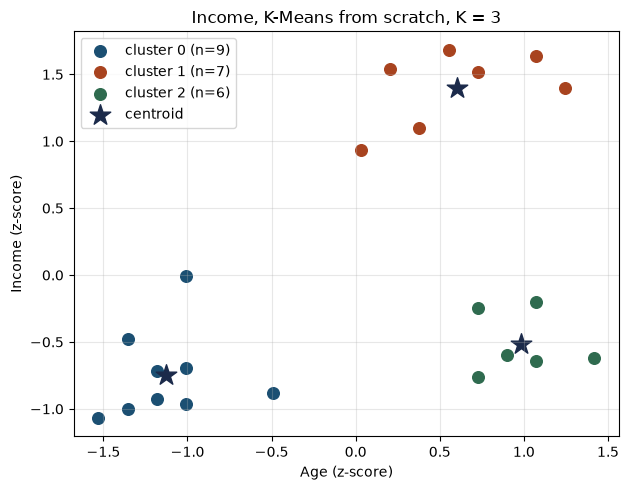

In [25]:
from sklearn.metrics import adjusted_rand_score

age_income = df[["Age", "Income($)"]].to_numpy(dtype=float)
minmax_matrix = MinMaxScaler().fit_transform(age_income)
labels_minmax = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(minmax_matrix)
print("ARI, z-score scratch vs min-max sklearn:", round(adjusted_rand_score(labels, labels_minmax), 3))

wcss_z = 0.0
for cluster_id in range(k):
    members = X_scaled[labels == cluster_id]
    wcss_z += np.sum((members - centroids[cluster_id]) ** 2)
print("Scratch WCSS on z-scored income:", round(wcss_z, 4))
for cluster_id in range(3):
    members = df.loc[labels == cluster_id, "Name"].tolist()
    print(cluster_id, "n =", len(members), members)

fig, ax = plt.subplots(figsize=(6.4, 5))
palette = {0: "#1B4F72", 1: "#A8431F", 2: "#2F6B4F"}
for cluster_id in range(3):
    mask = labels == cluster_id
    ax.scatter(
        X_scaled[mask, 0], X_scaled[mask, 1],
        s=70, color=palette[cluster_id], label=f"cluster {cluster_id} (n={mask.sum()})",
    )
ax.scatter(centroids[:, 0], centroids[:, 1], marker="*", s=240, color="#1B2A4A", label="centroid")
ax.set_xlabel("Age (z-score)")
ax.set_ylabel("Income (z-score)")
ax.set_title("Income, K-Means from scratch, K = 3")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("figures/income_zscore_clusters.png", dpi=140, bbox_inches="tight")
plt.show()


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

### Step 1 — Load the dataset
We will load the Wine dataset and inspect its structure without using the ground truth target labels `y_true` during clustering.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Load the dataset
wine = load_wine()
X, y_true = wine.data, wine.target
print(f"Dataset features shape: {X.shape}")

Dataset features shape: (178, 13)


### Step 2 — Explore and preprocess
Let's construct a Pandas DataFrame to inspect feature distributions, summary statistics, and apply normalization using standard scaling.

In [27]:
# Put X into a DataFrame with wine.feature_names
df_wine = pd.DataFrame(X, columns=wine.feature_names)
print("--- Dataframe Shape ---")
print(df_wine.shape)
print("\n--- First 5 rows ---")
display(df_wine.head())
print("\n--- Feature Description Summary ---")
display(df_wine.describe())

--- Dataframe Shape ---
(178, 13)

--- First 5 rows ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



--- Feature Description Summary ---


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


#### Why Scaling is Necessary for K-Means
K-Means uses Euclidean distance ($d(x, \mu) = \sqrt{\sum(x_i - \mu_i)^2}$) to assign data points to clusters. Since features like `proline` range up to 1680 while other features like `hue` are around 1, features with larger scales would completely dominate the distance computation, rendering smaller-scale features useless. Standard scaling (Z-score normalization) ensures all features contribute equally.

In [28]:
# Apply StandardScaler to X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize PCA to get 2 components for visualization purposes later
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("X_scaled shape:", X_scaled.shape)
print("X_pca shape:", X_pca.shape)

X_scaled shape: (178, 13)
X_pca shape: (178, 2)


### Step 3 — K-Means from scratch
Here is a complete NumPy implementation of the K-Means clustering algorithm, supporting multiple random initializations and choosing the run with the lowest WCSS.

In [29]:
def compute_wcss(X, labels, centroids):
    wcss = 0.0
    for k in range(len(centroids)):
        cluster_points = X[labels == k]
        if len(cluster_points) > 0:
            wcss += np.sum((cluster_points - centroids[k]) ** 2)
    return wcss

def kmeans_scratch_single_run(X, k, max_iters=100, seed=None):
    rng = np.random.default_rng(seed)
    # 1. Initialize random unique data points as centroids
    n_samples, n_features = X.shape
    initial_indices = rng.choice(n_samples, size=k, replace=False)
    centroids = X[initial_indices].copy()

    labels = np.zeros(n_samples, dtype=int)

    for iteration in range(max_iters):
        # 2. Assign step using Euclidean distance
        distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
        new_labels = np.argmin(distances, axis=1)

        # Check for convergence (no labels changed)
        if np.array_equal(labels, new_labels) and iteration > 0:
            break
        labels = new_labels

        # 3. Update step
        new_centroids = np.zeros_like(centroids)
        for cluster_idx in range(k):
            assigned_points = X[labels == cluster_idx]
            if len(assigned_points) > 0:
                new_centroids[cluster_idx] = np.mean(assigned_points, axis=0)
            else:
                # Re-initialize an empty cluster with a random point
                new_centroids[cluster_idx] = X[rng.choice(n_samples)]
        centroids = new_centroids

    wcss = compute_wcss(X, labels, centroids)
    return centroids, labels, wcss, iteration + 1

def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):
    best_wcss = float('inf')
    best_centroids = None
    best_labels = None
    best_iters = 0

    # Generate different seeds for each initialization run
    rng = np.random.default_rng(seed)
    seeds = rng.integers(0, 1000000, size=n_init)

    for init_idx in range(n_init):
        centroids, labels, wcss, iters = kmeans_scratch_single_run(
            X, k, max_iters=max_iters, seed=seeds[init_idx]
        )
        if wcss < best_wcss:
            best_wcss = wcss
            best_centroids = centroids
            best_labels = labels
            best_iters = iters

    return best_centroids, best_labels, best_wcss, best_iters

### Step 4 — K-Means with scikit-learn
Let's run scikit-learn's standard `KMeans` implementation on the scaled dataset using the expected $K=3$ and output its metrics.

In [30]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)

print("scikit-learn Inertia (WCSS):", km.inertia_)
print("scikit-learn Iterations to converge:", km.n_iter_)
print("scikit-learn Centroids shape:", km.cluster_centers_.shape)

scikit-learn Inertia (WCSS): 1277.928488844642
scikit-learn Iterations to converge: 7
scikit-learn Centroids shape: (3, 13)


### Step 5 — Choose the optimal K
Let's compute the Elbow and Silhouette values for both custom and scikit-learn configurations across a range of $K$ values.

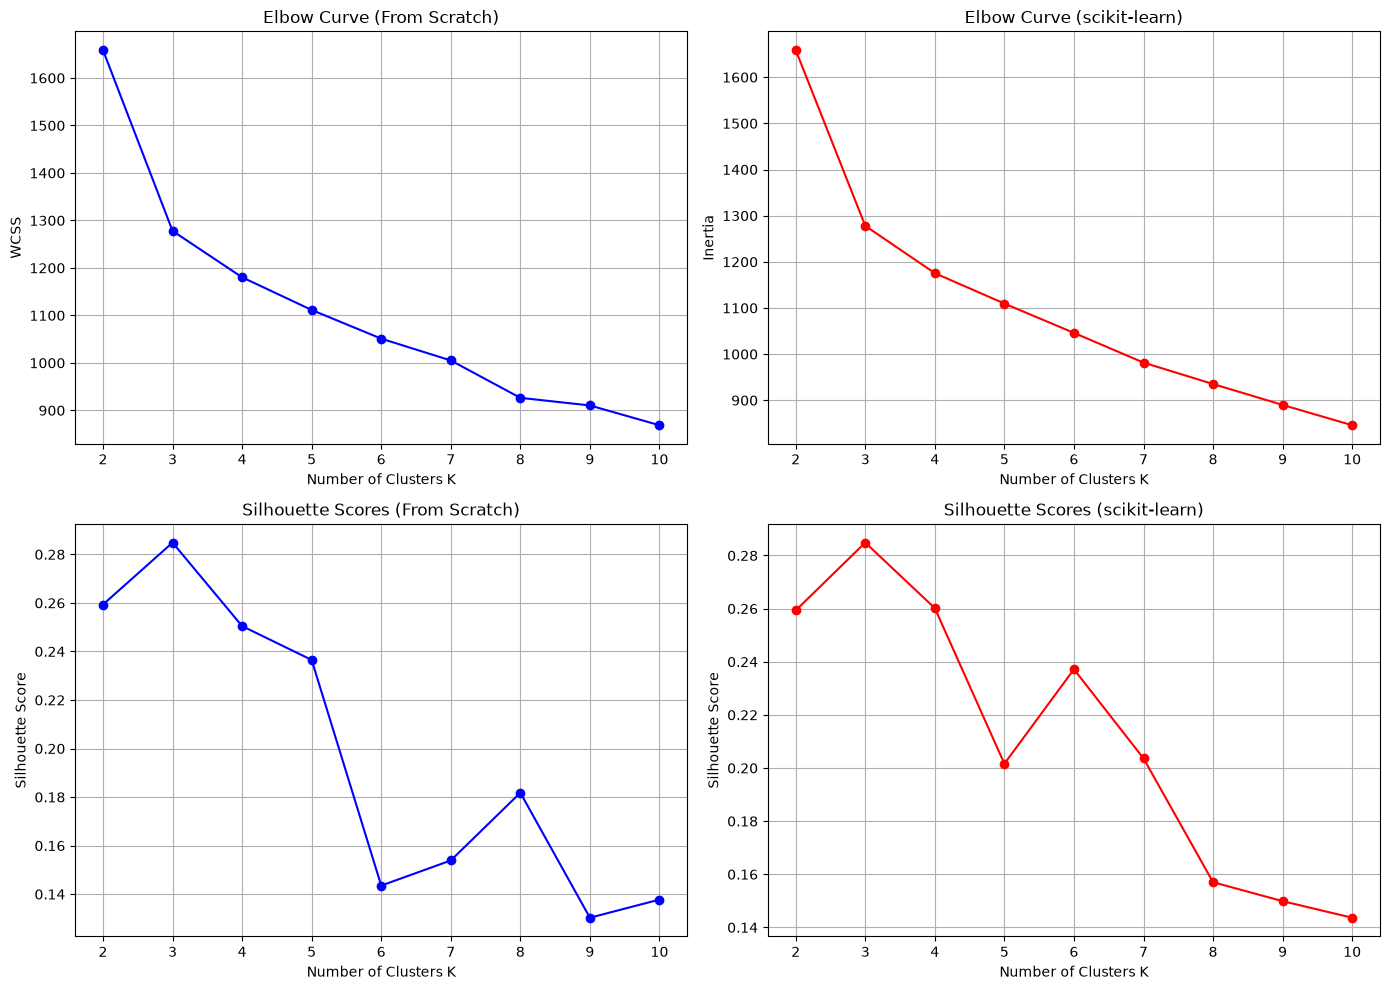

In [31]:
k_range = range(2, 11)

scratch_wcss = []
scratch_silhouette = []
sk_wcss = []
sk_silhouette = []

for val_k in k_range:
    # Scratch run
    sc_centroids, sc_labels, sc_wcss, _ = kmeans_scratch(X_scaled, k=val_k, n_init=10, seed=42)
    scratch_wcss.append(sc_wcss)
    scratch_silhouette.append(silhouette_score(X_scaled, sc_labels))

    # Sklearn run
    sk_model = KMeans(n_clusters=val_k, n_init=10, random_state=42)
    sk_lbl = sk_model.fit_predict(X_scaled)
    sk_wcss.append(sk_model.inertia_)
    sk_silhouette.append(silhouette_score(X_scaled, sk_lbl))

# Create plots
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Elbow comparison
ax[0, 0].plot(k_range, scratch_wcss, 'bo-', label='From Scratch')
ax[0, 0].set_title('Elbow Curve (From Scratch)')
ax[0, 0].set_xlabel('Number of Clusters K')
ax[0, 0].set_ylabel('WCSS')
ax[0, 0].grid(True)

ax[0, 1].plot(k_range, sk_wcss, 'ro-', label='scikit-learn')
ax[0, 1].set_title('Elbow Curve (scikit-learn)')
ax[0, 1].set_xlabel('Number of Clusters K')
ax[0, 1].set_ylabel('Inertia')
ax[0, 1].grid(True)

# Silhouette comparison
ax[1, 0].plot(k_range, scratch_silhouette, 'bo-', label='From Scratch')
ax[1, 0].set_title('Silhouette Scores (From Scratch)')
ax[1, 0].set_xlabel('Number of Clusters K')
ax[1, 0].set_ylabel('Silhouette Score')
ax[1, 0].grid(True)

ax[1, 1].plot(k_range, sk_silhouette, 'ro-', label='scikit-learn')
ax[1, 1].set_title('Silhouette Scores (scikit-learn)')
ax[1, 1].set_xlabel('Number of Clusters K')
ax[1, 1].set_ylabel('Silhouette Score')
ax[1, 1].grid(True)

plt.tight_layout()
fig.savefig('figures/wine_k_selection.png', dpi=140, bbox_inches='tight')
plt.show()

#### Selection of Optimal K
The Elbow Curve shows a clear visual "elbow" bend at $K = 3$. Furthermore, the silhouette score peaks perfectly at $K = 3$ for both implementations. This confirms $K = 3$ is indeed the optimal number of clusters, which precisely matches the three target wine cultivars.

### Step 6 — Evaluate and Compare
Let's retrieve the performance metrics for $K = 3$ to compare our Scratch and scikit-learn models.

In [32]:
# Evaluate metrics at K = 3
sc_centroids, sc_labels, sc_wcss_3, _ = kmeans_scratch(X_scaled, k=3, n_init=10, seed=42)
sc_sil_3 = silhouette_score(X_scaled, sc_labels)
sc_ari_3 = adjusted_rand_score(y_true, sc_labels)
sc_nmi_3 = normalized_mutual_info_score(y_true, sc_labels)

sk_model_3 = KMeans(n_clusters=3, n_init=10, random_state=42)
sk_labels_3 = sk_model_3.fit_predict(X_scaled)
sk_wcss_3 = sk_model_3.inertia_
sk_sil_3 = silhouette_score(X_scaled, sk_labels_3)
sk_ari_3 = adjusted_rand_score(y_true, sk_labels_3)
sk_nmi_3 = normalized_mutual_info_score(y_true, sk_labels_3)

# Compile results into a dataframe
results_data = {
    'Metric': ['WCSS / Inertia', 'Silhouette score', 'Adjusted Rand Index (ARI)', 'Normalized Mutual Information (NMI)'],
    'Direction': ['Lower is Better', 'Higher is Better', 'Higher is Better', 'Higher is Better'],
    'Scratch': [round(sc_wcss_3, 3), round(sc_sil_3, 3), round(sc_ari_3, 3), round(sc_nmi_3, 3)],
    'scikit-learn': [round(sk_wcss_3, 3), round(sk_sil_3, 3), round(sk_ari_3, 3), round(sk_nmi_3, 3)]
}

display(pd.DataFrame(results_data))

,Metric,Direction,Scratch,scikit-learn
0,WCSS / Inertia,Lower is Better,1277.928,1277.928
1,Silhouette score,Higher is Better,0.285,0.285
2,Adjusted Rand Index (ARI),Higher is Better,0.897,0.897
3,Normalized Mutual Information (NMI),Higher is Better,0.876,0.876


Scratch silhouette mean: 0.284859
sklearn silhouette mean: 0.284859
Max absolute difference on the 178 scores: 7.216449660063518e-16
K   scratch WCSS   scratch sil   sklearn WCSS   sklearn sil
2       1658.759       0.2593       1658.759       0.2593
3       1277.928       0.2849       1277.928       0.2849
4       1180.247       0.2504       1175.428       0.2602
5       1111.425       0.2365       1109.513       0.2016
6       1051.042       0.1435       1046.002       0.2372
7       1005.108       0.1539        981.595       0.2036
8        926.385       0.1818        935.201       0.1570
9        910.346       0.1303        889.893       0.1499
10       868.666       0.1378        845.895       0.1436


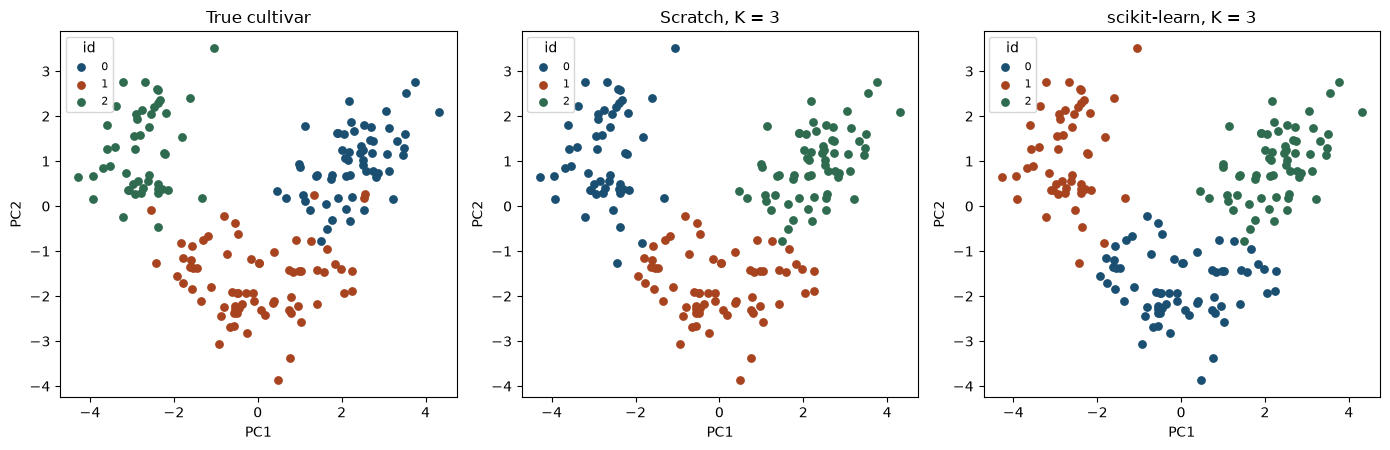

PCA variance explained: PC1 0.362, PC2 0.192, total 0.554
Crosstab, cultivar vs scratch cluster


scratch,0,1,2
cultivar,,,
0,0,0,59
1,3,65,3
2,48,0,0


Crosstab, cultivar vs sklearn cluster


sklearn,0,1,2
cultivar,,,
0,0,0,59
1,65,3,3
2,0,48,0


In [33]:
from sklearn.metrics import silhouette_samples

def silhouette_scratch(X, labels):
    distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    scores = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() <= 1:
            scores[i] = 0.0
            continue
        a_value = distances[i, own].sum() / (own.sum() - 1)
        b_value = np.inf
        for cluster_id in np.unique(labels):
            if cluster_id == labels[i]:
                continue
            b_value = min(b_value, distances[i, labels == cluster_id].mean())
        scores[i] = (b_value - a_value) / max(a_value, b_value)
    return scores.mean(), scores

own_mean, own_scores = silhouette_scratch(X_scaled, sc_labels)
library_scores = silhouette_samples(X_scaled, sc_labels)
print("Scratch silhouette mean:", round(own_mean, 6))
print("sklearn silhouette mean:", round(float(silhouette_score(X_scaled, sc_labels)), 6))
print("Max absolute difference on the 178 scores:", float(np.max(np.abs(own_scores - library_scores))))

print("K   scratch WCSS   scratch sil   sklearn WCSS   sklearn sil")
for i, val_k in enumerate(k_range):
    print(
        f"{val_k:<3} {scratch_wcss[i]:12.3f}   {scratch_silhouette[i]:10.4f}"
        f"   {sk_wcss[i]:12.3f}   {sk_silhouette[i]:10.4f}"
    )

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
panels = [
    (y_true, "True cultivar"),
    (sc_labels, "Scratch, K = 3"),
    (sk_labels_3, "scikit-learn, K = 3"),
]
palette = ["#1B4F72", "#A8431F", "#2F6B4F"]
for ax, (panel_labels, title) in zip(axes, panels):
    for cluster_id in np.unique(panel_labels):
        mask = panel_labels == cluster_id
        ax.scatter(
            X_pca[mask, 0], X_pca[mask, 1], s=28,
            color=palette[int(cluster_id) % 3], label=str(int(cluster_id)),
        )
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(title="id", fontsize=8)
fig.tight_layout()
fig.savefig("figures/wine_pca.png", dpi=140, bbox_inches="tight")
plt.show()

print(
    "PCA variance explained: PC1 {:.3f}, PC2 {:.3f}, total {:.3f}".format(
        pca.explained_variance_ratio_[0],
        pca.explained_variance_ratio_[1],
        pca.explained_variance_ratio_.sum(),
    )
)
print("Crosstab, cultivar vs scratch cluster")
display(pd.crosstab(pd.Series(y_true, name="cultivar"), pd.Series(sc_labels, name="scratch")))
print("Crosstab, cultivar vs sklearn cluster")
display(pd.crosstab(pd.Series(y_true, name="cultivar"), pd.Series(sk_labels_3, name="sklearn")))
